Dataset loaded successfully.
Dataset shape: (20640, 10)

First five rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values by column:


,Missing Values
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target variable distribution:


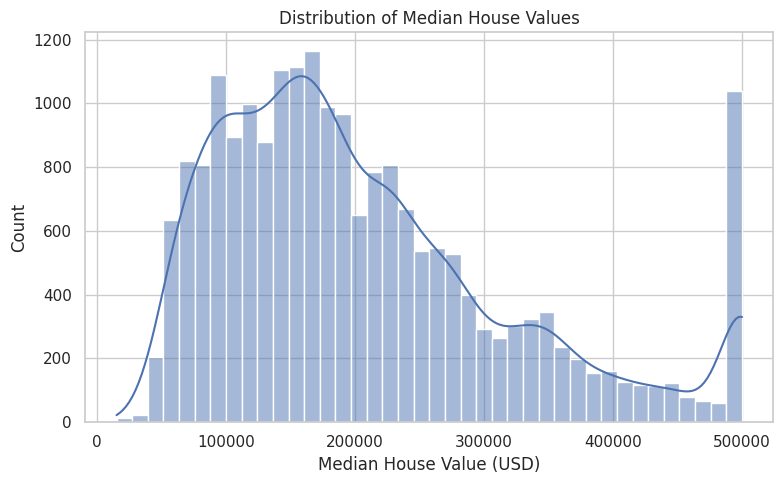

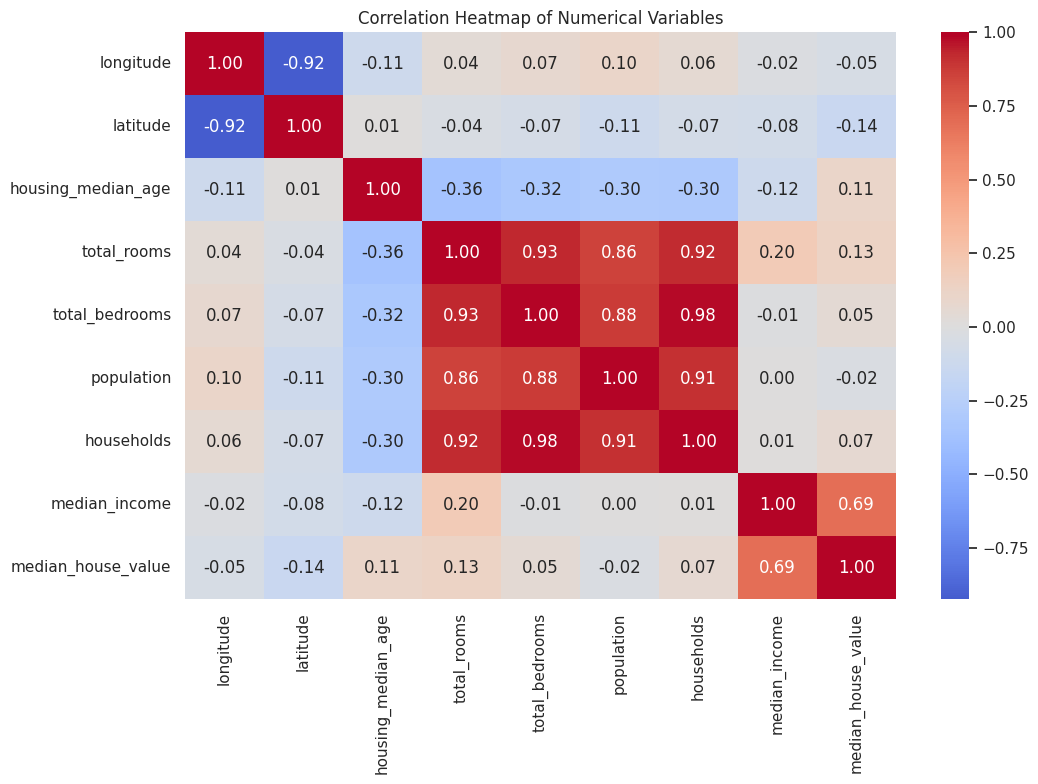


Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical features: ['ocean_proximity']

Training rows: 16512
Testing rows: 4128

Training OLS model...
Tuning Ridge Regression...
Tuning Lasso Regression...

Best Ridge alpha: 100.0
Best Lasso alpha: 100.0
Best Ridge CV RMSE: 77730.74
Best Lasso CV RMSE: 94483.19

TEST-SET MODEL COMPARISON


,Model,RMSE (USD),MAE (USD),R² Score
2,Lasso Regression,66504.974,47484.974,0.662
1,Ridge Regression,66506.897,47496.765,0.662
0,OLS (Linear Regression),179952.036,69788.741,-1.471


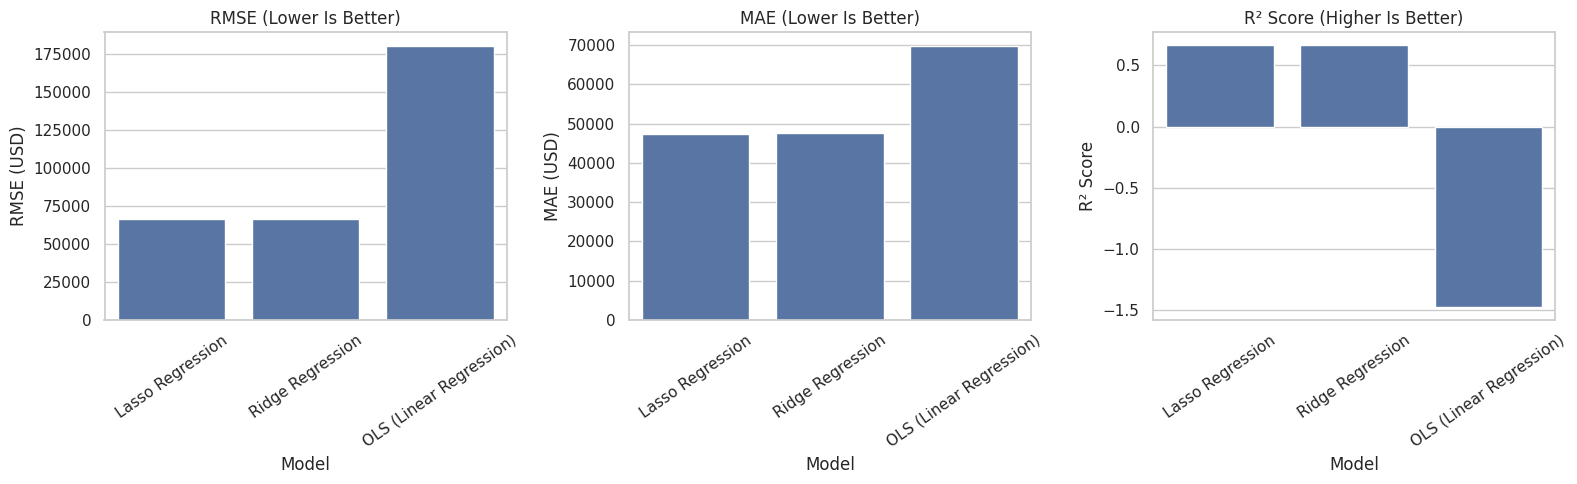

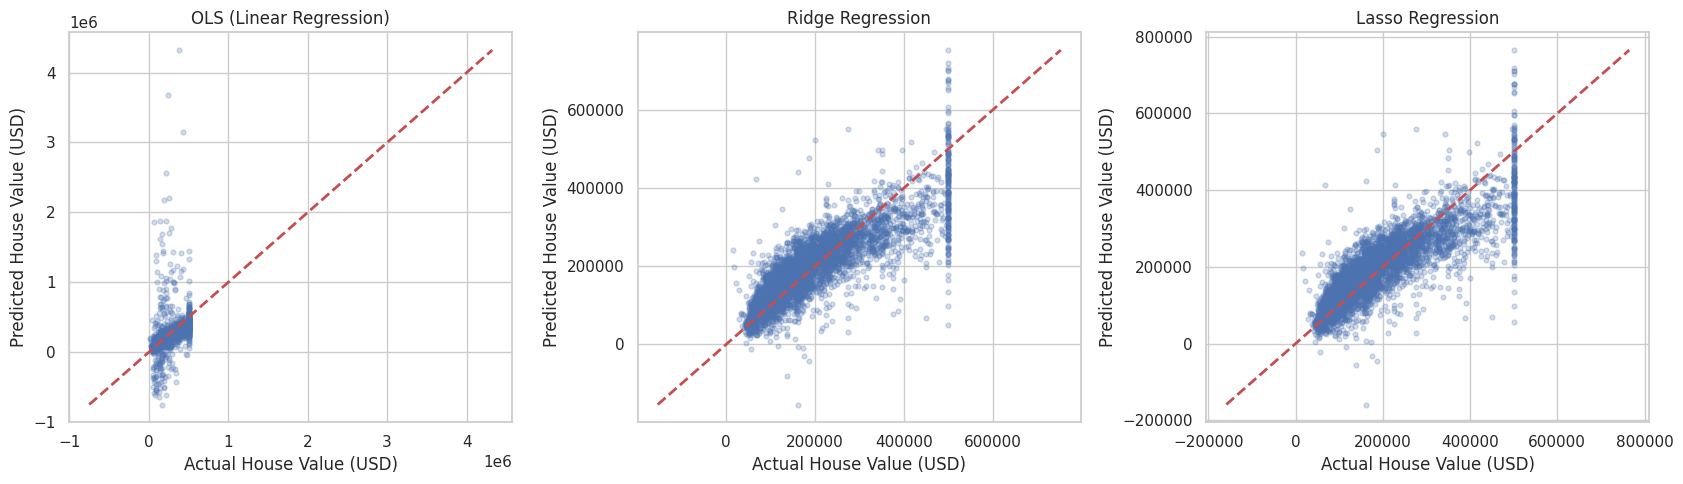

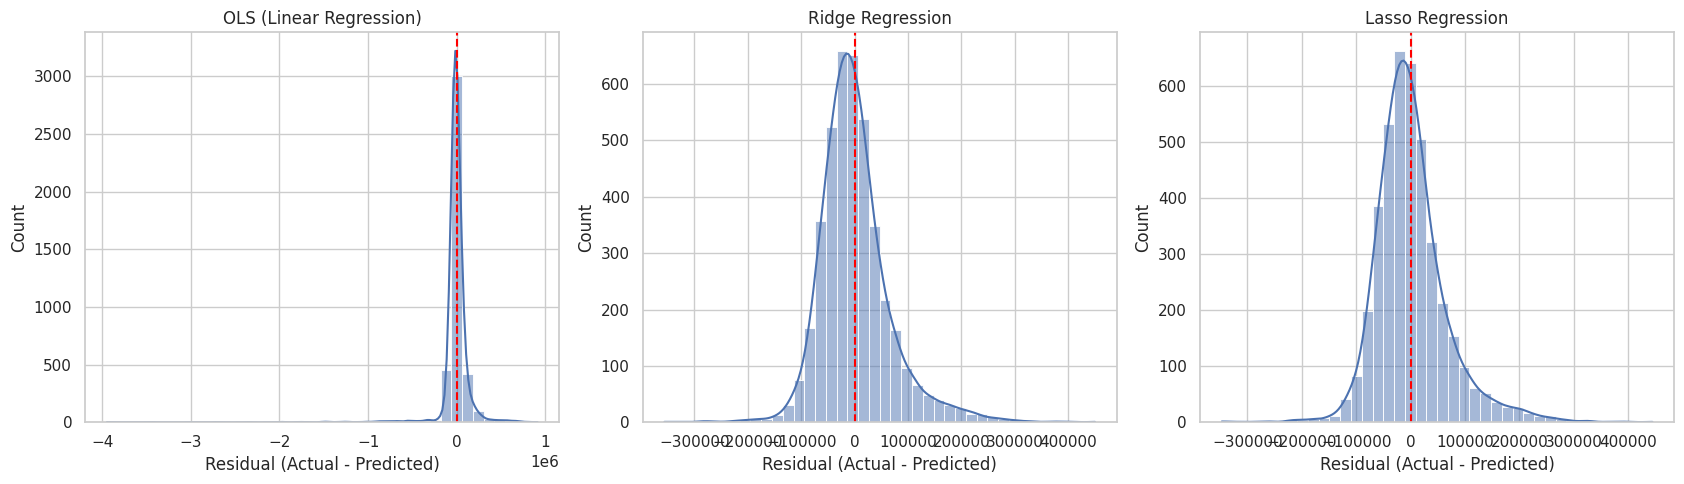

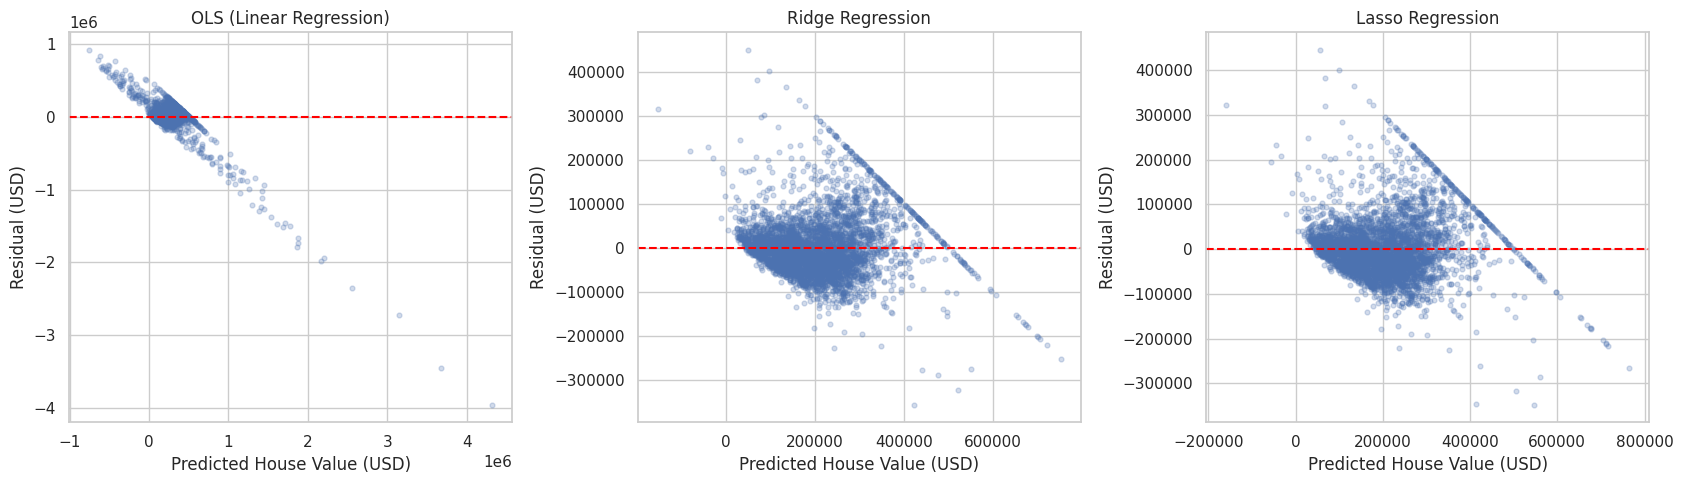


PROJECT SUMMARY
Dataset rows: 20640
Number of input features after manual feature engineering: 12
Train/test split: 80% / 20%
Models compared: OLS, Ridge, Lasso
Best Ridge alpha: 100.0
Best Lasso alpha: 100.0

Output files saved in task2_outputs/:
- actual_vs_predicted.png
- correlation_heatmap.png
- model_comparison.csv
- model_metrics_comparison.png
- residual_distributions.png
- residuals_vs_predicted.png
- target_distribution.png

Task 2 analysis completed.


In [1]:

# ============================================================
# TASK 2: REAL ESTATE HOUSING PRICE PREDICTION
# OLS vs Ridge (L2) vs Lasso (L1) Regression
# ============================================================

# 1. Import libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("task2_outputs", exist_ok=True)

# 2. Load the California Housing dataset
DATA_URL = (
    "https://raw.githubusercontent.com/ageron/"
    "handson-ml2/master/datasets/housing/housing.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

# 3. Basic data exploration
print("\nSummary statistics:")
display(df.describe(include="all").T)

print("\nTarget variable distribution:")
plt.figure(figsize=(8, 5))
sns.histplot(df["median_house_value"], bins=40, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (USD)")
plt.tight_layout()
plt.savefig("task2_outputs/target_distribution.png", dpi=300)
plt.show()

# 4. Correlation heatmap for numerical variables
numeric_for_corr = df.select_dtypes(include=np.number)

plt.figure(figsize=(11, 8))
sns.heatmap(
    numeric_for_corr.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.savefig("task2_outputs/correlation_heatmap.png", dpi=300)
plt.show()

# 5. Separate features and target
X = df.drop(columns=["median_house_value"]).copy()
y = df["median_house_value"].copy()

# 6. Feature engineering
# Ratios and interaction terms can help capture useful relationships.
# Infinite values are replaced with NaN and handled by the imputer.

X["rooms_per_household"] = (
    X["total_rooms"] / X["households"].replace(0, np.nan)
)
X["bedrooms_per_room"] = (
    X["total_bedrooms"] / X["total_rooms"].replace(0, np.nan)
)
X["population_per_household"] = (
    X["population"] / X["households"].replace(0, np.nan)
)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

# 7. Split data before fitting preprocessing steps to prevent leakage
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# 8. Preprocessing pipelines
# Missing numerical values: median imputation
# Interaction features: pairwise products of numerical features
# Scaling: StandardScaler
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# 9. Define models
ols_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ridge_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

lasso_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=20000))
])

# 10. Tune Ridge and Lasso using cross-validation
alpha_values = [0.01, 0.1, 1.0, 10.0, 100.0]

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

print("\nTraining OLS model...")
ols_model.fit(X_train, y_train)

print("Tuning Ridge Regression...")
ridge_search.fit(X_train, y_train)

print("Tuning Lasso Regression...")
lasso_search.fit(X_train, y_train)

best_ridge = ridge_search.best_estimator_
best_lasso = lasso_search.best_estimator_

print("\nBest Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("Best Ridge CV RMSE:", round(-ridge_search.best_score_, 2))
print("Best Lasso CV RMSE:", round(-lasso_search.best_score_, 2))

# 11. Evaluate all models on the held-out test set
models = {
    "OLS (Linear Regression)": ols_model,
    "Ridge Regression": best_ridge,
    "Lasso Regression": best_lasso
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE (USD)": rmse,
        "MAE (USD)": mae,
        "R² Score": r2
    })

results_df = pd.DataFrame(results).sort_values("RMSE (USD)")

print("\nTEST-SET MODEL COMPARISON")
display(results_df.round(3))

results_df.to_csv(
    "task2_outputs/model_comparison.csv",
    index=False
)

# 12. Plot model performance metrics
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=results_df, x="Model", y="RMSE (USD)", ax=axes[0]
)
axes[0].set_title("RMSE (Lower Is Better)")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=results_df, x="Model", y="MAE (USD)", ax=axes[1]
)
axes[1].set_title("MAE (Lower Is Better)")
axes[1].tick_params(axis="x", rotation=35)

sns.barplot(
    data=results_df, x="Model", y="R² Score", ax=axes[2]
)
axes[2].set_title("R² Score (Higher Is Better)")
axes[2].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig("task2_outputs/model_metrics_comparison.png", dpi=300)
plt.show()

# 13. Actual vs predicted plots
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.25, s=12)

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--",
        linewidth=2
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Value (USD)")
    ax.set_ylabel("Predicted House Value (USD)")

plt.tight_layout()
plt.savefig("task2_outputs/actual_vs_predicted.png", dpi=300)
plt.show()

# 14. Residual distribution curves
# Residual = actual value - predicted value
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred

    sns.histplot(
        residuals,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.savefig("task2_outputs/residual_distributions.png", dpi=300)
plt.show()

# 15. Residuals versus predicted values
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test.to_numpy() - y_pred

    ax.scatter(y_pred, residuals, alpha=0.25, s=12)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted House Value (USD)")
    ax.set_ylabel("Residual (USD)")

plt.tight_layout()
plt.savefig("task2_outputs/residuals_vs_predicted.png", dpi=300)
plt.show()

# 16. Final summary
print("\nPROJECT SUMMARY")
print("Dataset rows:", len(df))
print("Number of input features after manual feature engineering:", X.shape[1])
print("Train/test split: 80% / 20%")
print("Models compared: OLS, Ridge, Lasso")
print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])
print("\nOutput files saved in task2_outputs/:")
for filename in sorted(os.listdir("task2_outputs")):
    print("-", filename)

print("\nTask 2 analysis completed.")
